In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

L_lswt = 64
J_lswt = 1.0
q0_lswt = np.pi / 4
D_lswt = J_lswt * np.tan(q0_lswt)
J2_lswt = J_lswt / (4 * np.cos(q0_lswt))

x_lswt = np.arange(L_lswt)
phi_lswt = q0_lswt * x_lswt

spiral0 = np.column_stack((
    np.zeros(L_lswt),
    np.cos(phi_lswt),
    np.sin(phi_lswt)
))

tangent_a = np.tile(np.array([1.0, 0.0, 0.0]), (L_lswt, 1))
tangent_b = np.column_stack((
    np.zeros(L_lswt),
    -np.sin(phi_lswt),
    np.cos(phi_lswt)
))

ex_lswt = np.array([1.0, 0.0, 0.0])
output_dir = Path("lswt_validation")
output_dir.mkdir(exist_ok=True)

print("L =", L_lswt, "q0 =", q0_lswt, "D =", D_lswt, "J2 =", J2_lswt)

L = 64 q0 = 0.7853981633974483 D = 0.9999999999999999 J2 = 0.35355339059327373


In [2]:
def normalize_spins(spins):
    return spins / np.linalg.norm(spins, axis=-1, keepdims=True)


def effective_field(spins, model):
    sxp = np.roll(spins, -1, axis=0)
    sxm = np.roll(spins, 1, axis=0)

    field = J_lswt * (sxp + sxm + 2 * spins)

    if model == "dmi":
        field += D_lswt * np.cross(sxp - sxm, ex_lswt)
    elif model == "frustration":
        field -= J2_lswt * (
            np.roll(spins, -2, axis=0)
            + np.roll(spins, 2, axis=0)
        )

    return field


def spin_rhs(spins, model):
    return -np.cross(spins, effective_field(spins, model))


def spin_energy(spins, model):
    E = -J_lswt * np.sum(spins * np.roll(spins, -1, axis=0))
    E -= J_lswt * np.sum(spins * spins)

    if model == "dmi":
        E += D_lswt * np.sum(
            spins * np.cross(ex_lswt, np.roll(spins, -1, axis=0))
        )
    else:
        E += J2_lswt * np.sum(
            spins * np.roll(spins, -2, axis=0)
        )

    return E

In [3]:
def lswt_frequency(k, model):
    if model == "dmi":
        lam = (
            2 * J_lswt * (1 + np.cos(q0_lswt))
            + 2 * D_lswt * np.sin(q0_lswt)
        )

        A = lam - 2 * J_lswt * (np.cos(k) + 1)

        B = lam - 2 * (
            (J_lswt * np.cos(q0_lswt) + D_lswt * np.sin(q0_lswt))
            * np.cos(k)
            + J_lswt
        )

    else:
        lam = (
            2 * J_lswt * (1 + np.cos(q0_lswt))
            - 2 * J2_lswt * np.cos(2 * q0_lswt)
        )

        A = (
            lam
            - 2 * J_lswt * (np.cos(k) + 1)
            + 2 * J2_lswt * np.cos(2 * k)
        )

        B = (
            lam
            - 2 * J_lswt * (np.cos(q0_lswt) * np.cos(k) + 1)
            + 2 * J2_lswt * np.cos(2 * q0_lswt) * np.cos(2 * k)
        )

    return np.sqrt(np.maximum(A * B, 0))

In [4]:
def numerical_lswt_frequency(k, model, epsilon=1e-6):
    wave = np.cos(k * x_lswt)
    denominator = np.sum(wave ** 2)
    matrix = np.zeros((2, 2))

    for column, tangent in enumerate((tangent_a, tangent_b)):
        perturbation = wave[:, None] * tangent

        plus = normalize_spins(spiral0 + epsilon * perturbation)
        minus = normalize_spins(spiral0 - epsilon * perturbation)

        derivative = (
            spin_rhs(plus, model) - spin_rhs(minus, model)
        ) / (2 * epsilon)

        matrix[0, column] = np.sum(derivative[:, 0] * wave) / denominator

        matrix[1, column] = np.sum(
            np.sum(derivative * tangent_b, axis=1) * wave
        ) / denominator

    eigenvalues = np.linalg.eigvals(matrix)
    return np.max(np.abs(np.imag(eigenvalues)))

DMI-x equilibrium torque: 1.0658141036401503e-14
Frustration equilibrium torque: 5.329070518200751e-15
DMI-x maximum frequency error: 5.47929072106362e-06
Frustration maximum frequency error: 3.0395746727149063e-07


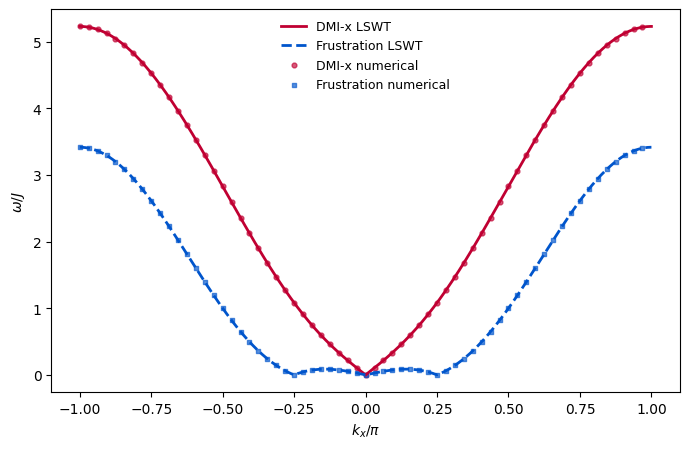

In [5]:
k_grid = np.linspace(-np.pi, np.pi, 1001)
k_lattice = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(L_lswt))

omega_dmi_analytic = lswt_frequency(k_grid, "dmi")
omega_fr_analytic = lswt_frequency(k_grid, "frustration")

omega_dmi_numeric = np.array([
    numerical_lswt_frequency(k, "dmi") for k in k_lattice
])

omega_fr_numeric = np.array([
    numerical_lswt_frequency(k, "frustration") for k in k_lattice
])

error_dmi = np.max(np.abs(
    omega_dmi_numeric - lswt_frequency(k_lattice, "dmi")
))

error_fr = np.max(np.abs(
    omega_fr_numeric - lswt_frequency(k_lattice, "frustration")
))

torque_dmi = np.max(np.abs(spin_rhs(spiral0, "dmi")))
torque_fr = np.max(np.abs(spin_rhs(spiral0, "frustration")))

print("DMI-x equilibrium torque:", torque_dmi)
print("Frustration equilibrium torque:", torque_fr)
print("DMI-x maximum frequency error:", error_dmi)
print("Frustration maximum frequency error:", error_fr)

assert error_dmi < 1e-5
assert error_fr < 1e-5

fig, ax = plt.subplots(figsize=(7, 4.6))

ax.plot(k_grid / np.pi, omega_dmi_analytic, color="#C00032", lw=2, label="DMI-x LSWT")
ax.plot(k_grid / np.pi, omega_fr_analytic, color="#0055CC", lw=2, ls="--", label="Frustration LSWT")

ax.scatter(k_lattice / np.pi, omega_dmi_numeric, color="#C00032", marker="o", s=12, alpha=0.65, label="DMI-x numerical")
ax.scatter(k_lattice / np.pi, omega_fr_numeric, color="#0055CC", marker="s", s=12, alpha=0.65, label="Frustration numerical")

ax.set_xlabel(r"$k_x/\pi$")
ax.set_ylabel(r"$\omega/J$")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

fig.savefig(output_dir / "lswt_numerical_validation.pdf", bbox_inches="tight")
fig.savefig(output_dir / "lswt_numerical_validation.png", dpi=400, bbox_inches="tight")
plt.show()

In [6]:
def rk4_step(spins, dt, model):
    k1 = spin_rhs(spins, model)
    k2 = spin_rhs(normalize_spins(spins + 0.5 * dt * k1), model)
    k3 = spin_rhs(normalize_spins(spins + 0.5 * dt * k2), model)
    k4 = spin_rhs(normalize_spins(spins + dt * k3), model)

    return normalize_spins(
        spins + (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
    )


def simulate_spin_wave(model, k, dt=0.025, steps=4096, amplitude=0.0005):
    initial = spiral0 + (
        amplitude * np.cos(k * x_lswt)[:, None] * tangent_a
    )

    spins = normalize_spins(initial)
    E_initial = spin_energy(spins, model)

    signal = np.zeros(steps)

    for n in range(steps):
        projection = np.sum((spins - spiral0) * tangent_a, axis=1)
        signal[n] = 2 * np.mean(
            projection * np.cos(k * x_lswt)
        )

        spins = rk4_step(spins, dt, model)

    t = dt * np.arange(steps)

    fft = np.fft.rfft(
        (signal - signal.mean()) * np.hanning(steps)
    )

    frequencies = 2 * np.pi * np.fft.rfftfreq(steps, dt)
    power = np.abs(fft) ** 2

    peak = np.argmax(power[1:]) + 1

    y1, y2, y3 = np.log(power[peak-1:peak+2] + 1e-35)
    correction = 0.5 * (y1 - y3) / (y1 - 2 * y2 + y3)

    measured = (peak + correction) * (frequencies[1] - frequencies[0])

    E_final = spin_energy(spins, model)
    norm_error = np.max(
        np.abs(np.linalg.norm(spins, axis=1) - 1)
    )

    return t, signal, frequencies, power, measured, E_final - E_initial, norm_error

DMI-x       theory=2.828427  dynamics=2.828893  error=0.000466
Frustration theory=1.000000  dynamics=1.000981  error=0.000981
DMI-x energy drift: -8.037659426918253e-11
Frustration energy drift: -2.842170943040401e-14
DMI-x spin norm error: 0.0
Frustration spin norm error: 0.0


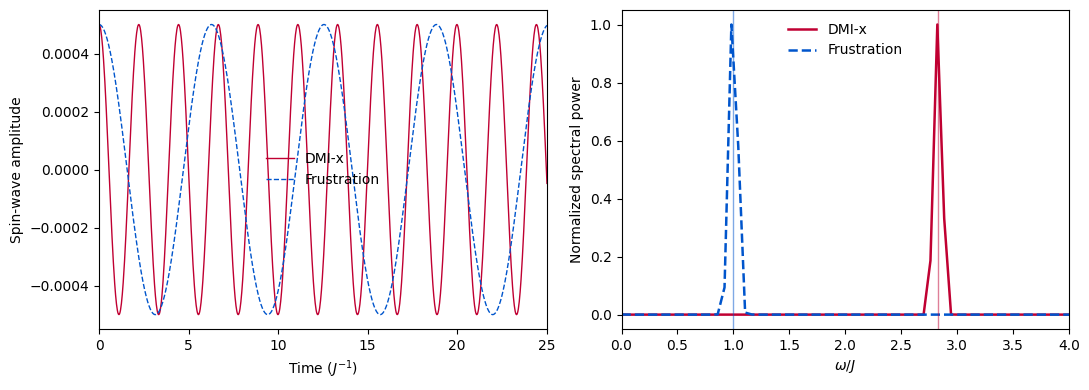

In [7]:
k_test = np.pi / 2

time_dmi, signal_dmi, freq_dmi, power_dmi, measured_dmi, drift_dmi, norm_dmi = simulate_spin_wave("dmi", k_test)
time_fr, signal_fr, freq_fr, power_fr, measured_fr, drift_fr, norm_fr = simulate_spin_wave("frustration", k_test)

theory_dmi = lswt_frequency(k_test, "dmi")
theory_fr = lswt_frequency(k_test, "frustration")

print(f"DMI-x       theory={theory_dmi:.6f}  dynamics={measured_dmi:.6f}  error={abs(theory_dmi - measured_dmi):.6f}")
print(f"Frustration theory={theory_fr:.6f}  dynamics={measured_fr:.6f}  error={abs(theory_fr - measured_fr):.6f}")
print("DMI-x energy drift:", drift_dmi)
print("Frustration energy drift:", drift_fr)
print("DMI-x spin norm error:", norm_dmi)
print("Frustration spin norm error:", norm_fr)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(time_dmi, signal_dmi, color="#C00032", lw=1.0, label="DMI-x")
axes[0].plot(time_fr, signal_fr, color="#0055CC", lw=1.0, ls="--", label="Frustration")
axes[0].set_xlim(0, 25)
axes[0].set_xlabel(r"Time ($J^{-1}$)")
axes[0].set_ylabel("Spin-wave amplitude")
axes[0].legend(frameon=False)

axes[1].plot(freq_dmi, power_dmi / power_dmi.max(), color="#C00032", lw=1.8, label="DMI-x")
axes[1].plot(freq_fr, power_fr / power_fr.max(), color="#0055CC", lw=1.8, ls="--", label="Frustration")
axes[1].axvline(theory_dmi, color="#C00032", alpha=0.5, lw=1)
axes[1].axvline(theory_fr, color="#0055CC", alpha=0.5, lw=1)
axes[1].set_xlim(0, 4)
axes[1].set_xlabel(r"$\omega/J$")
axes[1].set_ylabel("Normalized spectral power")
axes[1].legend(frameon=False)

fig.tight_layout()
fig.savefig(output_dir / "spin_dynamics_frequency_check.pdf", bbox_inches="tight")
fig.savefig(output_dir / "spin_dynamics_frequency_check.png", dpi=400, bbox_inches="tight")
plt.show()

In [8]:
np.savez(
    output_dir / "lswt_validation_data.npz",
    k_lattice=k_lattice,
    omega_dmi_numeric=omega_dmi_numeric,
    omega_fr_numeric=omega_fr_numeric,
    omega_dmi_analytic=lswt_frequency(k_lattice, "dmi"),
    omega_fr_analytic=lswt_frequency(k_lattice, "frustration"),
    time=time_dmi,
    signal_dmi=signal_dmi,
    signal_frustration=signal_fr,
    frequencies=freq_dmi,
    power_dmi=power_dmi,
    power_frustration=power_fr
)

print("Saved in:", output_dir.resolve())

Saved in: /home/senji77/akhyar/research/notebooks/ANSW/lswt_validation
